![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | EDA and Baseline

*Project 2 — Machine Learning: From Data to Predictions*

**Team:** Rizki
**Dataset:**  Coffee Quality Institute (CQI) green-coffee reviews, Arabica samples (1,310 rows after cleaning). Scraped Jan 2018 by jldbc (github.com/jldbc/coffee-quality-database). The repo is MIT-licensed; the licence of CQI's underlying data is unclear (see references/sources.json).

---

Steps 1 to 4 of the workflow: frame the problem, look at the data, split once, and score the baseline every model will have to beat.

> **Done when:** your framing is written down, you know what is broken in the data and which columns must go, the split is fixed, and you have a baseline score from cross-validation.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. Frame the problem

Before any code. In a few sentences:

- **The question:** who or what you predict, for whom, and what they would do with the prediction.

Before anyone cups a green coffee, can we predict its cupping score from what we already know about the lot: country, variety, processing method, altitude, moisture, colour and defect counts? A buyer (for example a café like UNTU') could use it to decide which lots to taste first.

- **The target**, and for classification **the positive class**.

`Total.Cup.Points`, a number, so this is regression (there is no positive class).


- **The metric**, and why: which mistake costs more?

MAE, the average miss in cup points. It is easy to explain ("on average we are 1.2 points off") and not dominated by a few extreme scores. I also report R², the share of the variation we explain.
- **Which mistake costs more:** specialty coffee starts at about 80 points and most scores cluster around 82 to 84, so a miss of 1 to 2 points can move a lot of coffees across that line.

You wrote a first version on launch day. Update it here as the data teaches you things.
___________________________________________________________________________________
- Friday, 16 Oct 2026

===================================================================================



---
## 2. Load the raw data

Run `python download_data.py <houses|telco|bank|flowers>` from the repo root first. Your files land in `data/raw/`, which is gitignored.

In [2]:
import os
from src.config import PATHS, RANDOM_STATE   # paths and the seed live in ONE place: src/config.py

clean_path = os.path.join(PATHS["clean_data"], "cqi_clean.csv")
clean = pd.read_csv(clean_path)
print("data/clean/cqi_clean.csv")
print(clean.shape)                 # expect (1338, 20)
clean["species"].value_counts()    # expect arabica 1310, robusta 28

data/clean/cqi_clean.csv
(1338, 20)


species
arabica    1310
robusta      28
Name: count, dtype: int64

---
## 3. First look

Shape, column types, a handful of rows. What is one row of this data, and what is the target column?

In [3]:
# Robusta has only 28 rows and different score columns, so the models use Arabica only
df = clean[clean["species"] == "arabica"].copy()
print(df.shape)                    # expect (1310, 20)
df.head()

(1310, 20)


,species,Country.of.Origin,Variety,Processing.Method,Color,Moisture,Category.One.Defects,Category.Two.Defects,altitude_mean_meters,Total.Cup.Points,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points
0,arabica,Ethiopia,NaN,Washed / Wet,Green,0.12,0,0,2075.0,90.58,8.67,8.83,8.67,8.75,8.50,8.42,10.0,10.0,10.0,8.75
1,arabica,Ethiopia,Other,Washed / Wet,Green,0.12,0,1,2075.0,89.92,8.75,8.67,8.50,8.58,8.42,8.42,10.0,10.0,10.0,8.58
2,arabica,Guatemala,Bourbon,NaN,NaN,NaN,0,0,1700.0,89.75,8.42,8.50,8.42,8.42,8.33,8.42,10.0,10.0,10.0,9.25
3,arabica,Ethiopia,NaN,Natural / Dry,Green,0.11,0,2,2000.0,89.00,8.17,8.58,8.42,8.42,8.50,8.25,10.0,10.0,10.0,8.67
4,arabica,Ethiopia,Other,Washed / Wet,Green,0.12,0,2,2075.0,88.83,8.25,8.50,8.25,8.50,8.42,8.33,10.0,10.0,10.0,8.58


In [4]:
df.dtypes            # numbers should be numbers; text columns are the categories

species                  object
Country.of.Origin        object
Variety                  object
Processing.Method        object
Color                    object
Moisture                float64
Category.One.Defects      int64
Category.Two.Defects      int64
altitude_mean_meters    float64
Total.Cup.Points        float64
Aroma                   float64
Flavor                  float64
Aftertaste              float64
Acidity                 float64
Body                    float64
Balance                 float64
Uniformity              float64
Clean.Cup               float64
Sweetness               float64
Cupper.Points           float64
dtype: object

In [5]:
df.describe().T     # Moisture count should be about 1,020: the rest were emptied by the Cleaner

,count,mean,std,min,25%,50%,75%,max
Moisture,1004.0,0.111982,0.012478,0.06,0.11,0.11,0.12,0.15
Category.One.Defects,1310.0,0.426718,1.833077,0.00,0.00,0.00,0.00,31.00
Category.Two.Defects,1310.0,3.593130,5.352233,0.00,0.00,2.00,4.00,55.00
altitude_mean_meters,1052.0,1325.398170,387.116318,50.00,1100.00,1313.82,1600.00,2560.00
Total.Cup.Points,1310.0,82.178611,2.686039,59.83,81.17,82.50,83.67,90.58
Aroma,1310.0,7.569580,0.315845,5.08,7.42,7.58,7.75,8.75
Flavor,1310.0,7.523809,0.341897,6.08,7.33,7.58,7.75,8.83
Aftertaste,1310.0,7.403344,0.349867,6.17,7.25,7.42,7.58,8.67
Acidity,1310.0,7.538863,0.319912,5.25,7.33,7.50,7.75,8.75
Body,1310.0,7.523466,0.293129,5.25,7.33,7.50,7.67,8.58


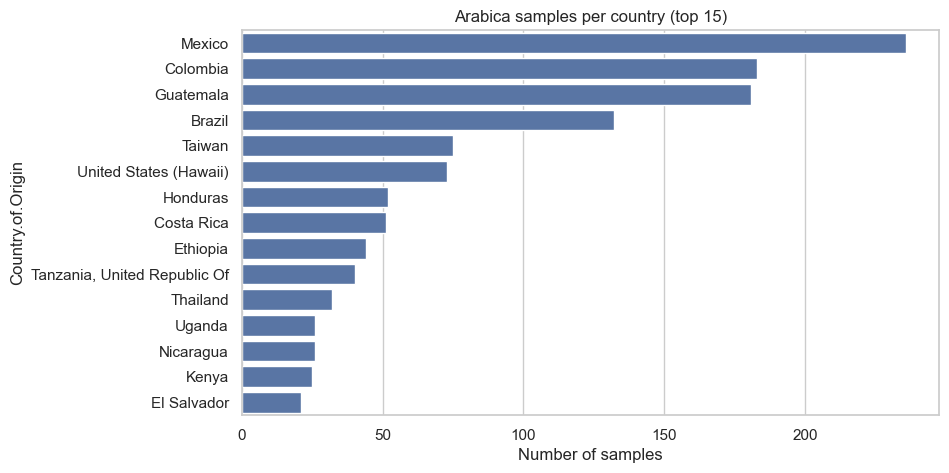

In [6]:
order = df["Country.of.Origin"].value_counts().head(15).index
plt.figure(figsize=(9, 5))
sns.countplot(data=df, y="Country.of.Origin", order=order)
plt.title("Arabica samples per country (top 15)")
plt.xlabel("Number of samples")
plt.show()

---
## 4. Data quality

Missing values (including ones in disguise, such as `"unknown"`, blanks or `999`), duplicates, numbers stored as text, dates stored as strings. Write down what you find and what you will do about it.

**What I found and what I did about it**
- Numbers stored as text ("12 %", "Sample 90.58") in the raw files: fixed by the Cleaner.
- Moisture of exactly 0.0 (252 Arabica rows): "not measured" in disguise, set to empty.
- Moisture between 0.01 and 0.05 (38 rows): impossible for green coffee, set to empty.
- Altitude above 3,000 m (14 rows) and below 50 m (17 rows): typing errors (for example "1.2" read as 12 m), set to empty.
- One row with a total of 0: dropped.
- Still open: the wet tail of moisture (see below).
- Gaps in Variety, Processing.Method, Color, Moisture and altitude are filled later, inside the Pipeline, learning only from the training set.

Moisture                23.4
Color                   20.4
altitude_mean_meters    19.7
Variety                 15.3
Processing.Method       11.5
Country.of.Origin        0.1
species                  0.0
Acidity                  0.0
Sweetness                0.0
Clean.Cup                0.0
Uniformity               0.0
Balance                  0.0
Body                     0.0
Aroma                    0.0
Aftertaste               0.0
Flavor                   0.0
Total.Cup.Points         0.0
Category.Two.Defects     0.0
Category.One.Defects     0.0
Cupper.Points            0.0
dtype: float64


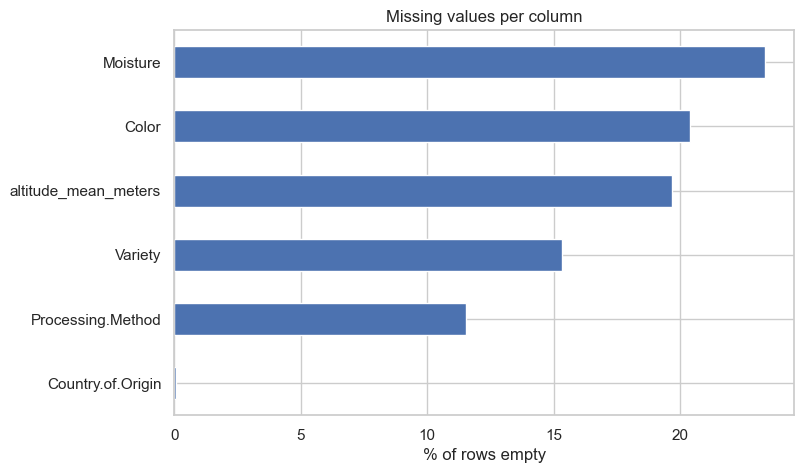

In [7]:
# 4a. How much is empty in each column?
missing = df.isna().mean().sort_values(ascending=False) * 100
print(missing.round(1))

plt.figure(figsize=(8, 5))
missing[missing > 0].plot.barh()
plt.xlabel("% of rows empty")
plt.title("Missing values per column")
plt.gca().invert_yaxis()
plt.show()

In [8]:
# 4b. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
# 4c. What did the Cleaner already fix? One line per step, straight from its report
import json
with open("../references/cleaning_report.json") as f:
    report = json.load(f)
pd.json_normalize(report)

,dataset_id,run_date,based_on,steps,rule_counts,low_altitude_rows,high_moisture_top10,altitude_near_2500_rows,checks,robusta_empty_columns.columns,robusta_empty_columns.why,final.rows_per_species.arabica,final.rows_per_species.robusta,final.columns,final.column_names
0,ds_cqi_jldbc_2018,2026-10-16,"[references/gate2_decisions.json, references/c...","[{'step': 'load_arabica', 'rows_before': 1311,...","[{'rule': 'moisture_zero_to_missing', 'real': ...","[{'species': 'arabica', 'Country.of.Origin': '...","[{'species': 'arabica', 'Country.of.Origin': '...","[{'species': 'arabica', 'Country.of.Origin': '...","[{'check': 'arabica rows loaded', 'real': 1311...","[Acidity, Body, Sweetness]",the Robusta matches for these columns are gues...,1310,28,20,"[species, Country.of.Origin, Variety, Processi..."


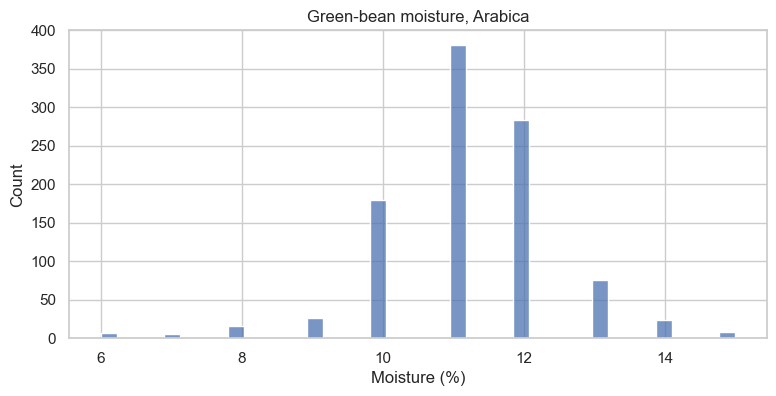

,Country.of.Origin,Moisture,Total.Cup.Points
123,El Salvador,0.15,84.75
557,Colombia,0.15,82.92
727,Mexico,0.15,82.33
772,Mexico,0.15,82.17
777,Indonesia,0.15,82.08
1078,Mexico,0.15,80.50
1120,Mexico,0.15,80.08
1255,Mexico,0.15,77.33


In [10]:
# 4d. Moisture is stored as a fraction (0.11 = 11 %), so show it as a percent
plt.figure(figsize=(9, 4))
sns.histplot(df["Moisture"] * 100, bins=40)
plt.xlabel("Moisture (%)")
plt.title("Green-bean moisture, Arabica")
plt.show()

wet = df[df["Moisture"] > 0.14][["Country.of.Origin", "Moisture", "Total.Cup.Points"]]
wet.sort_values("Moisture", ascending=False)      # expect 24 rows, up to 0.28

In [11]:
# How many rows would each possible limit remove?
for limit in [0.13, 0.14, 0.15, 0.16, 0.18, 0.20]:
    print(f"moisture above {limit:.2f}: {(df['Moisture'] > limit).sum()} rows")

moisture above 0.13: 31 rows
moisture above 0.14: 8 rows
moisture above 0.15: 0 rows
moisture above 0.16: 0 rows
moisture above 0.18: 0 rows
moisture above 0.20: 0 rows


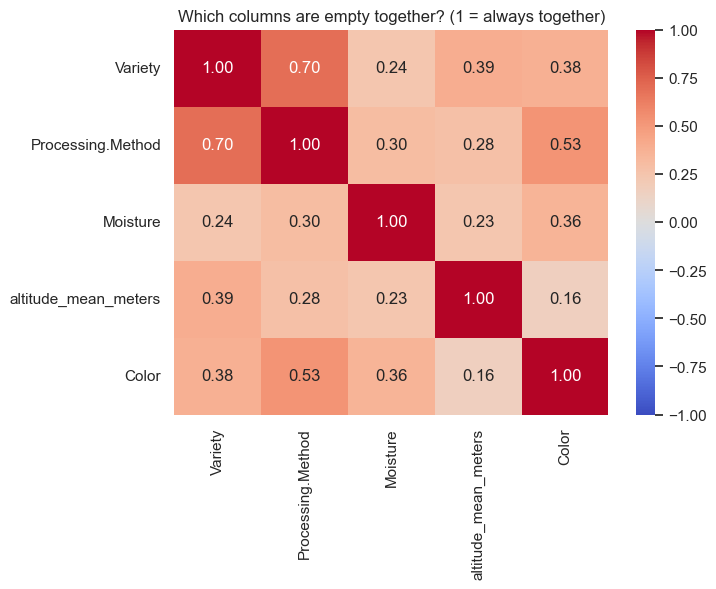

Processing.Method
False    0.187
True     0.589
Name: Moisture, dtype: float64

In [12]:
# 4e. Are the gaps random, or do columns go empty together?
gap_cols = ["Variety", "Processing.Method", "Moisture", "altitude_mean_meters", "Color"]
gaps = df[gap_cols].isna().astype(int)       # 1 = empty

plt.figure(figsize=(7, 5))
sns.heatmap(gaps.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Which columns are empty together? (1 = always together)")
plt.show()

# share of empty Moisture, split by whether Processing.Method is empty
df["Moisture"].isna().groupby(df["Processing.Method"].isna()).mean().round(3)

---
## 5. Columns that must go

Identifiers, and **anything that would not be known at the moment you make a prediction**. List them with the reason. A column that looks too good to be true usually is.

- **The ten part scores** (Aroma … Cupper.Points): Total.Cup.Points is their sum, and they only exist after cupping. When we predict (before cupping) we don't have them. They stay in the table for the globe and for clustering.
- **species**: after filtering to Arabica it is the same value in every row.
- Identifiers (farm, lot, mill, owner) and personal-data columns were already dropped by the Cleaner.

In [13]:
TARGET = "Total.Cup.Points"
part_scores = ["Aroma", "Flavor", "Aftertaste", "Acidity", "Body", "Balance",
               "Uniformity", "Clean.Cup", "Sweetness", "Cupper.Points"]

# Proof they are the ingredients of the target: the gap between their sum and the total
gap = (df[part_scores].sum(axis=1) - df[TARGET]).abs()
gap.describe()          # max should be tiny (rounding only)

count    1310.000000
mean        0.006008
std         0.015109
min         0.000000
25%         0.000000
50%         0.010000
75%         0.010000
max         0.500000
dtype: float64

In [14]:
defect_cols = [c for c in df.columns if "Defects" in c]
numeric_features = ["Moisture", "altitude_mean_meters"] + defect_cols
categorical_features = ["Country.of.Origin", "Variety", "Processing.Method", "Color"]
features = numeric_features + categorical_features

print("Expected but not found:", [c for c in features + part_scores + [TARGET] if c not in df.columns])
print("Features:", features)
print("Not features:", [c for c in df.columns if c not in features + [TARGET]])

Expected but not found: []
Features: ['Moisture', 'altitude_mean_meters', 'Category.One.Defects', 'Category.Two.Defects', 'Country.of.Origin', 'Variety', 'Processing.Method', 'Color']
Not features: ['species', 'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Uniformity', 'Clean.Cup', 'Sweetness', 'Cupper.Points']


---
## 6. The target

Its distribution. For classification, the share of each class: this is what makes accuracy honest or misleading. For regression, is it skewed?

count    1310.000000
mean       82.178611
std         2.686039
min        59.830000
25%        81.170000
50%        82.500000
75%        83.670000
max        90.580000
Name: Total.Cup.Points, dtype: float64
skew: -1.84
share below 80 points: 13.7 %


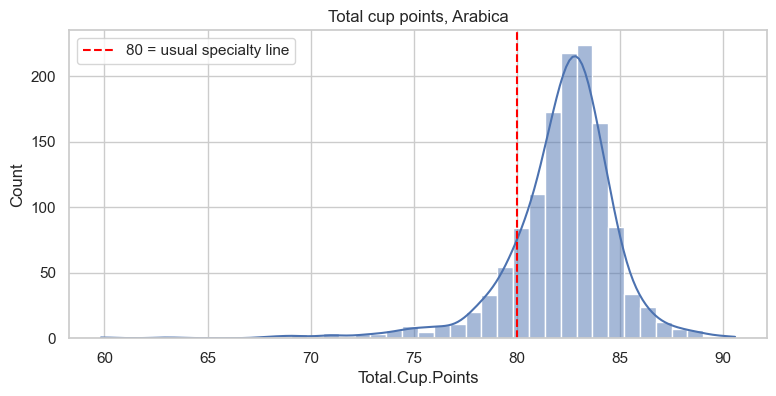

In [15]:
y = df[TARGET]
print(y.describe())
print("skew:", round(y.skew(), 2))
print("share below 80 points:", round((y < 80).mean() * 100, 1), "%")

plt.figure(figsize=(9, 4))
sns.histplot(y, bins=40, kde=True)
plt.axvline(80, color="red", linestyle="--", label="80 = usual specialty line")
plt.legend()
plt.title("Total cup points, Arabica")
plt.show()

---
## 7. Features against the target

Which features move with the target, and how? Numeric against target, categories against target. Write the takeaway under each chart.

In [16]:
# Numeric features: how strongly does each move with the score?
df[numeric_features + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()

Category.Two.Defects   -0.286653
Category.One.Defects   -0.145318
Moisture               -0.138923
altitude_mean_meters    0.228319
Name: Total.Cup.Points, dtype: float64

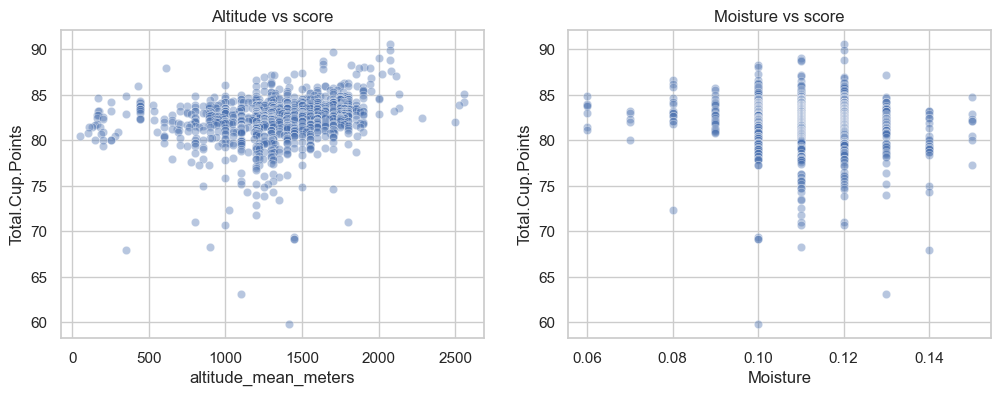

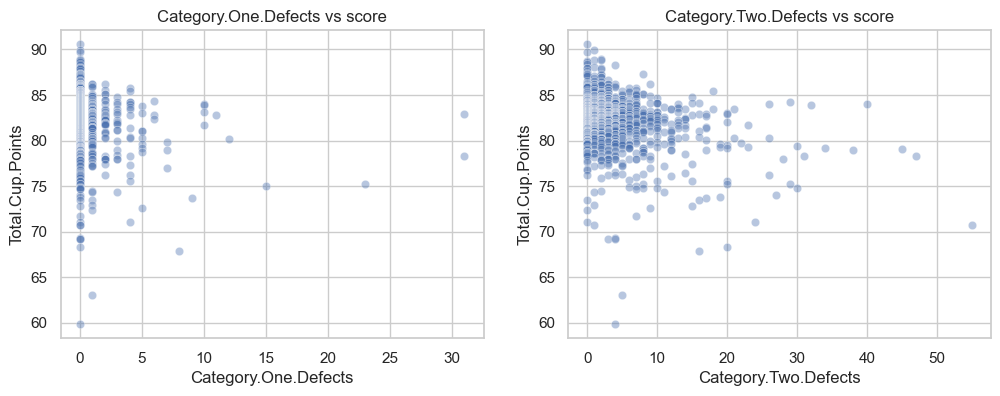

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="altitude_mean_meters", y=TARGET, alpha=0.4, ax=axes[0])
sns.scatterplot(data=df, x="Moisture", y=TARGET, alpha=0.4, ax=axes[1])
axes[0].set_title("Altitude vs score")
axes[1].set_title("Moisture vs score")
plt.show()

fig, axes = plt.subplots(1, len(defect_cols), figsize=(12, 4))
for ax, col in zip(np.atleast_1d(axes), defect_cols):
    sns.scatterplot(data=df, x=col, y=TARGET, alpha=0.4, ax=ax)
    ax.set_title(f"{col} vs score")
plt.show()

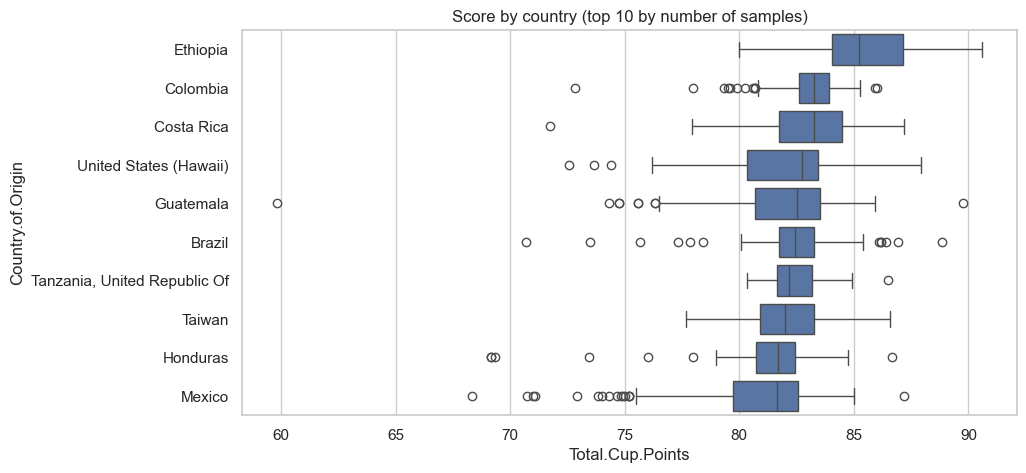

In [18]:
# Categories vs score: country first (top 10 by number of samples), sorted by median score
top_countries = df["Country.of.Origin"].value_counts().head(10).index
sub = df[df["Country.of.Origin"].isin(top_countries)]
order = sub.groupby("Country.of.Origin")[TARGET].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 5))
sns.boxplot(data=sub, x=TARGET, y="Country.of.Origin", order=order)
plt.title("Score by country (top 10 by number of samples)")
plt.show()

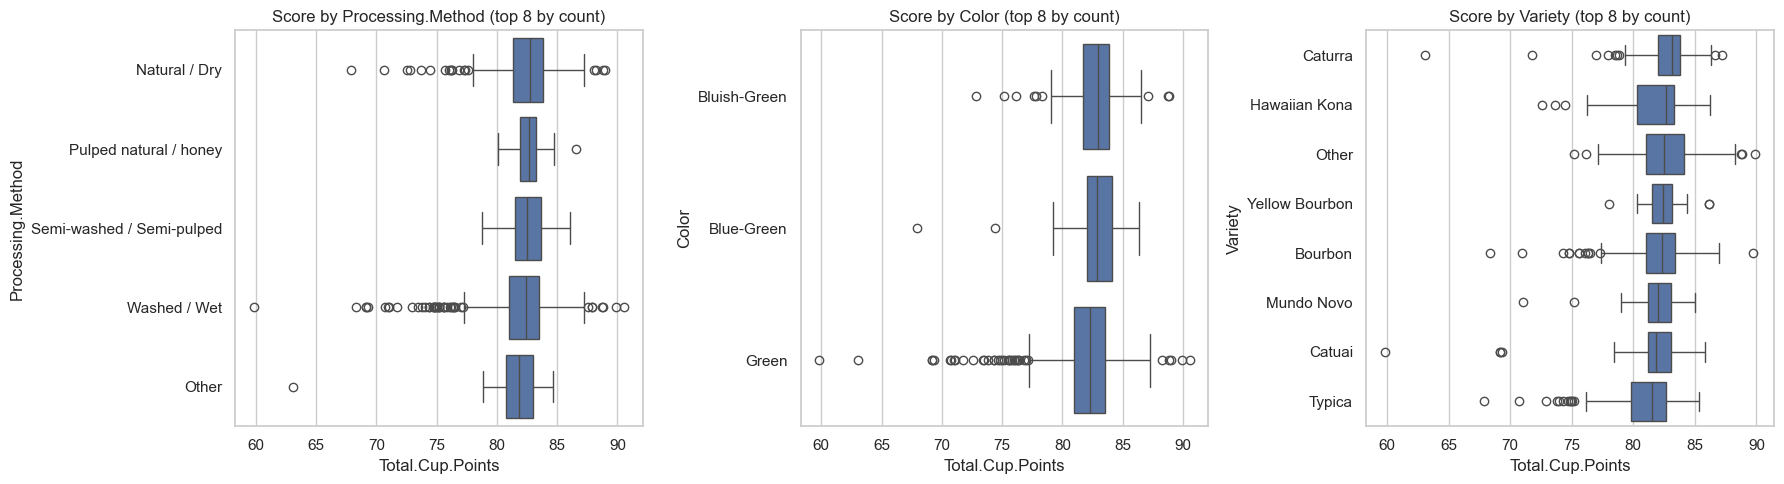

In [19]:
# The same for processing method, colour and variety (top 8 categories each)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["Processing.Method", "Color", "Variety"]):
    top = df[col].value_counts().head(8).index
    sub = df[df[col].isin(top)]
    order = sub.groupby(col)[TARGET].median().sort_values(ascending=False).index
    sns.boxplot(data=sub, x=TARGET, y=col, order=order, ax=ax)
    ax.set_title(f"Score by {col} (top 8 by count)")
plt.tight_layout()
plt.show()

---
## 8. Split once

A fixed `random_state`, stratified for classification. From here on, everything happens on the training set; the test set waits until notebook 03.

In [20]:
from sklearn.model_selection import train_test_split

X = df[features]
y = df[TARGET]
# Regression, so no stratify. The seed comes from src/config.py, so every notebook gets the same split.
X_train, X_test, y_train, y_test = split_once(df, RANDOM_STATE)
print(X_train.shape, X_test.shape)      # expect (1048, 8) and (262, 8)

pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(2)

(1048, 8) (262, 8)


,train,test
count,1048.00,262.00
mean,82.20,82.10
std,2.69,2.67
min,59.83,67.92
25%,81.17,81.08
50%,82.50,82.62
75%,83.67,83.65
max,90.58,87.08


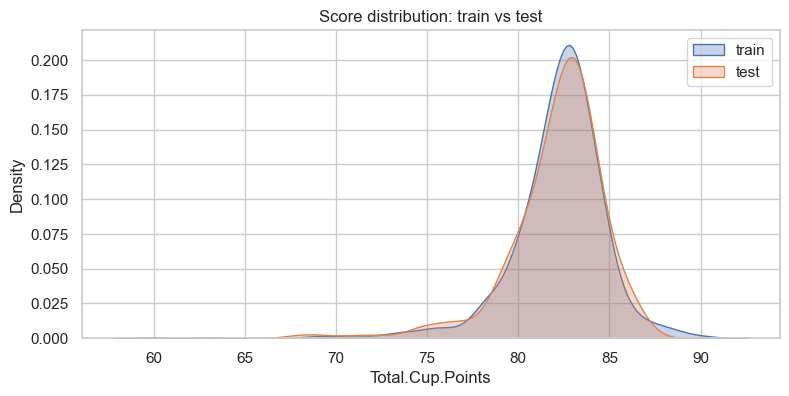

In [21]:
plt.figure(figsize=(9, 4))
sns.kdeplot(y_train, label="train", fill=True, alpha=0.3)
sns.kdeplot(y_test, label="test", fill=True, alpha=0.3)
plt.legend()
plt.title("Score distribution: train vs test")
plt.show()

---
## 9. Baseline

A `DummyClassifier` or `DummyRegressor`, scored with the cross-validation you will use for every model. Write the number down: it is what next week's models have to beat.

In [22]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score

# The same 5 folds will be used for every model in notebook 02
cv = make_cv(RANDOM_STATE)

baseline = DummyRegressor(strategy="mean")   # always says "about the average score"

mae = -cross_val_score(baseline, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
r2 = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="r2")
print("Baseline MAE:", mae.mean().round(3), "+/-", mae.std().round(3))
print("Baseline R2: ", r2.mean().round(3))
print("typical score:", round(y_train.mean(), 2), "| spread (std):", round(y_train.std(), 2))

Baseline MAE: 1.819 +/- 0.156
Baseline R2:  -0.003
typical score: 82.2 | spread (std): 2.69


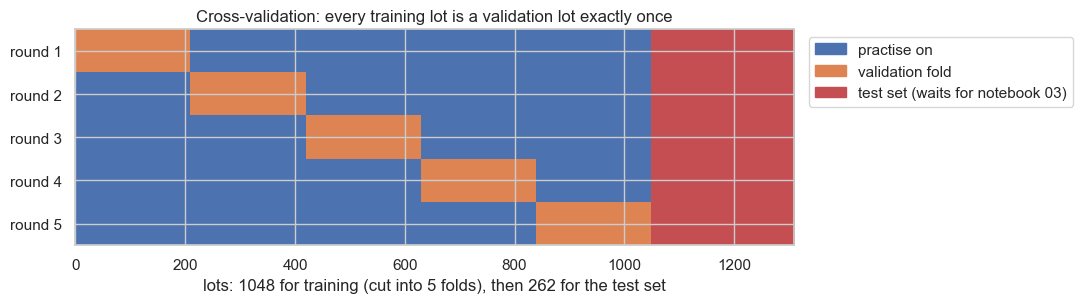

In [23]:
# How the 5 folds cut the training lots, and where the test set waits.
# Each row is one practice round: blue lots are practised on, orange lots are the held-out validation fold.
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

n_train, n_test = len(X_train), len(X_test)
n_folds = cv.get_n_splits()

fold_of = np.zeros(n_train, dtype=int)
for fold, (_, validation_idx) in enumerate(cv.split(X_train)):
    fold_of[validation_idx] = fold
lot_order = np.argsort(fold_of, kind="stable")             # lots grouped by the fold they validate in

grid = np.zeros((n_folds, n_train + n_test))               # 0 = practise on, 1 = validation fold, 2 = test set
for fold in range(n_folds):
    grid[fold, :n_train] = (fold_of[lot_order] == fold)
grid[:, n_train:] = 2                                      # the test lots: not touched until notebook 03

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.imshow(grid, aspect="auto", interpolation="nearest", cmap=ListedColormap(["C0", "C1", "C3"]))
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f"round {i + 1}" for i in range(n_folds)])
ax.set_xlabel(f"lots: {n_train} for training (cut into {n_folds} folds), then {n_test} for the test set")
ax.set_title("Cross-validation: every training lot is a validation lot exactly once")
ax.legend(handles=[Patch(color="C0", label="practise on"), Patch(color="C1", label="validation fold"),
                   Patch(color="C3", label="test set (waits for notebook 03)")],
          loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

---
## 10. Into notebook 02

The columns you keep and how each type will be prepared, the features you want to try, and the models you will compare.

**Columns kept:** Moisture, altitude_mean_meters, the two defect counts (numbers); Country.of.Origin, Variety, Processing.Method, Color (categories).
**Preparation, all inside a Pipeline, learning from the training set only:**
- numbers: fill gaps with the median; scale for models that need it
- categories: fill gaps with a "missing" label; one-hot encode; group rare varieties and countries
**Models to compare (same folds as the baseline):** three families from class, for example a linear model, a tree-based model and a third family.
**Unsupervised, for the globe:** cluster countries or lots on the seven informative part scores, leaving out Uniformity, Clean.Cup and Sweetness (almost always 10).
**Baseline to beat:** MAE = ___
**Open:** the moisture limit (cleaning v3).

---
## Image option

If you chose the flower photos, sections 3 to 7 become: a grid of example photos per class, the number of photos per class, the range of image sizes, and a few photos that are hard or look mislabelled. Section 8 is a fixed split into training, validation and test sets with `image_dataset_from_directory` and a seed. Section 9 is the majority-class accuracy.